In [5]:
import numpy as np

In [15]:
# ARRAYS AND SHAPES

vector1 = []
for i in range(10):
    if i <= 10:
        vector1.append(i)
        print(vector1)
    else:
        break

[0]
[0, 1]
[0, 1, 2]
[0, 1, 2, 3]
[0, 1, 2, 3, 4]
[0, 1, 2, 3, 4, 5]
[0, 1, 2, 3, 4, 5, 6]
[0, 1, 2, 3, 4, 5, 6, 7]
[0, 1, 2, 3, 4, 5, 6, 7, 8]
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [45]:
vector2 = np.array([[1,2],[3,4]])
vector2.shape

(2, 2)

In [66]:
v1 = np.arange(12)

In [67]:
print(v1)
print(v1.shape)
print(v1.ndim)
print(v1.dtype)

[ 0  1  2  3  4  5  6  7  8  9 10 11]
(12,)
1
int64


In [68]:
v1 = v1.reshape(3,4)

In [69]:
print(v1)
print(v1.shape)
print(v1.ndim)
print(v1.dtype)

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(3, 4)
2
int64


In [ ]:
# Indexing, Slicing and Masks

# array[start:end:step] (slicing)

In [80]:
print(v1[1:2]) # prints 2nd row of matrix

[[4 5 6 7]]


In [85]:
print(v1[:, -1]) # prints final row of matrix. note: [:, 3] would give the same result for this matrix, but not in general.

[ 3  7 11]


In [87]:
print(v1[1:2, 2]) # prints the element at row 2,  column 3

[6]


In [90]:
print(v1[0:2, 0:2]) # prints a 2x2 matrix from the top left of the 3x4 matrix

[[0 1]
 [4 5]]


In [92]:
print(v1[v1>5]) # prints every element in the matrix greater than 5

[ 6  7  8  9 10 11]


In [118]:
# Element-Wise vs Matrix Multiplication

A = np.arange(1,18,3)
A = A.reshape(2,3)
print(A)

B = np.arange(6)
B = B.reshape(3,2)
print(B)

[[ 1  4  7]
 [10 13 16]]
[[0 1]
 [2 3]
 [4 5]]


In [119]:
A @ B

array([[ 36,  48],
       [ 90, 129]])

In [121]:
B @ A

array([[ 10,  13,  16],
       [ 32,  47,  62],
       [ 54,  81, 108]])

In [123]:
A * A

array([[  1,  16,  49],
       [100, 169, 256]])

In [127]:
# A * B fails as A.shape ≠ B.shape

In [170]:
# One Layer of Neural Network

rng = np.random.default_rng(0) # random number generator

W = rng.standard_normal((3,4)) # weight matrix, W - using random values from Standard Normal Distribution N~(0,1)
#print(W)

b = rng.standard_normal((3)) # bias vector, b
#print(b)

x = rng.standard_normal(4) # input, x
#print(x)

z = W @ x + b
print(z)

X = rng.standard_normal((5,4))
transposeW = W.T # transposes weight matrix, W
X @ transposeW # X must go on the left side, so that the columns count of X matches the rows count in transposeW

[-2.50458535 -0.0459478   0.17228124]


array([[ 0.95339065,  0.54695523, -1.45017448],
       [-0.09294292, -0.44316477, -1.47996189],
       [-0.02031205, -0.34082705,  1.04890126],
       [ 0.36362224,  0.96303621,  0.02046673],
       [ 0.13028664,  0.14668859,  0.69046389]])

In [180]:
# Broadcasting

M = rng.standard_normal((5,3))
centeredM = M - M.mean(axis=0) # "centering" matrix M
np.allclose(centeredM.mean(axis=0), 0)

True

In [207]:
%%timeit
# dot product using regular Python
vector1 = rng.standard_normal(1000000)
vector2 = rng.standard_normal(1000000)
dProd = 0
for i in range(0, 1000000):
    dProd = dProd + (vector1[i] * vector2[i])

print(dProd)

808.690973867982
1552.2806215004928
24.80985830964389
1647.5857808449423
-308.1950683180346
793.8174048239403
61.28930508873708
27.020526274466608
607 ms ± 72.8 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [209]:
%%timeit
# Loops and Vectorisation

# dot product using np.dot
vector3 = rng.standard_normal(1000000)
vector4 = rng.standard_normal(1000000)
dP = np.dot(vector3, vector4)

print(dP)

-236.129350569316
-578.7097112592343
-772.9985637148419
-276.99071471929636
613.7085125391084
-417.83475018336344
683.8063875734383
-183.68926861373768
-878.186053179828
-467.6914011806405
306.8713180380969
142.5010605903385
-1328.4705295285319
-1563.2338439922667
993.4725364257145
27.49864200231309
203.45656731989504
-594.9426275094263
177.1895281140836
485.1970389732553
134.65765824650805
1200.0437950753503
-396.4702664185829
-730.700247661391
1850.9376227614027
-550.5590077809088
-546.3271339142887
-354.45361346421873
-272.40199462135973
-1418.9617999574868
983.1235692725802
2792.7452990136644
1279.36798784437
-1167.5953985537053
1120.0654314892781
1196.4127268396246
-173.3577376415068
1120.6290962422977
-180.13320812265215
-1321.975152482983
-939.2079603990745
-193.04353223426125
-345.5659351966001
-1242.3905369529602
253.72340037905911
-92.15780657010208
-377.19161421666865
1118.186406431474
392.8909418427851
570.7015988435928
1647.8802467206683
-267.448578656021
714.7237816538061

In [17]:
# Sigmoid and its Derivative

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_prime(z):
    return sigmoid(z) * (1 - sigmoid(z))

x = np.linspace(-8, 8, 200)

sigmoid(values)
sigmoid_prime(values)

array([0.00033524, 0.00036328, 0.00039368, 0.00042661, 0.00046229,
       0.00050096, 0.00054285, 0.00058825, 0.00063743, 0.00069073,
       0.00074847, 0.00081103, 0.00087882, 0.00095225, 0.00103181,
       0.001118  , 0.00121138, 0.00131253, 0.00142211, 0.0015408 ,
       0.00166937, 0.00180863, 0.00195946, 0.00212281, 0.00229972,
       0.0024913 , 0.00269875, 0.00292337, 0.00316657, 0.00342986,
       0.00371487, 0.00402338, 0.00435728, 0.00471862, 0.00510962,
       0.00553265, 0.00599028, 0.00648525, 0.00702054, 0.00759932,
       0.00822501, 0.00890126, 0.009632  , 0.01042144, 0.01127406,
       0.01219466, 0.01318834, 0.01426057, 0.01541713, 0.01666416,
       0.01800817, 0.01945605, 0.02101506, 0.02269282, 0.02449733,
       0.02643695, 0.0285204 , 0.03075669, 0.03315513, 0.03572528,
       0.03847689, 0.04141981, 0.04456394, 0.0479191 , 0.05149495,
       0.05530079, 0.05934545, 0.06363708, 0.06818291, 0.07298908,
       0.07806031, 0.08339965, 0.08900815, 0.09488453, 0.10102

In [18]:
import matplotlib.pyplot as plt

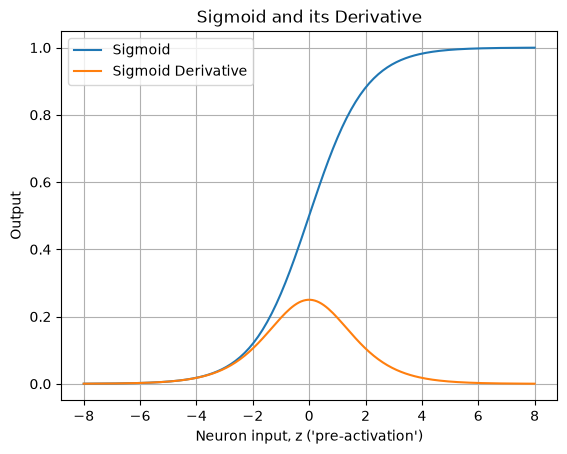

In [31]:
plt.plot(x, sigmoid(x), label="Sigmoid")
plt.plot(x, sigmoid_prime(x), label="Sigmoid Derivative")
plt.xlabel("Neuron input, z ('pre-activation')")
plt.ylabel("Output")
plt.legend()
plt.title("Sigmoid and its Derivative")
plt.grid(True)
plt.show()